In [364]:
import pandas as pd
import numpy as np
import joblib
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.metrics import precision_recall_curve

In [459]:
clf_test=joblib.load("../models/mod_XGB_optimizado.joblib")
#clf_test=joblib.load("../models/mod_XGB.joblib")

In [460]:
clf_test

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,0.5
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [461]:
X_test, y_test = joblib.load("../data/processed/test.joblib")

In [462]:
X_test.shape

(8911, 24)

In [463]:
y_test.shape

(8911,)

In [464]:
%%time
test_pred = clf_test.predict(X_test)

CPU times: total: 62.5 ms
Wall time: 32.5 ms


In [465]:
print("Test")
print(classification_report(y_test, test_pred))

Test
              precision    recall  f1-score   support

           0       0.83      0.78      0.81      5640
           1       0.66      0.73      0.69      3271

    accuracy                           0.76      8911
   macro avg       0.75      0.76      0.75      8911
weighted avg       0.77      0.76      0.77      8911



# Umbral de corte

In [466]:
X_train, y_train = joblib.load("../data/processed/train.joblib")

In [467]:
X_train.head(4)

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar
31742,1,40,170,80,3.80,0.00,0.00,0,0,4.58,...,1.83,6.08,0.67,0.04,0.04,1.25,1.54,1.83,0,1
7945,0,45,150,55,3.04,0.00,0.01,0,0,5.46,...,2.96,3.54,0.55,0.04,0.04,0.71,0.50,0.46,0,1
27480,1,40,170,60,3.09,0.01,0.00,0,0,5.08,...,3.46,4.79,0.63,0.04,0.04,0.83,0.33,1.13,0,1
32289,0,40,150,45,2.92,0.04,0.04,0,0,5.42,...,2.92,5.79,0.50,0.04,0.01,0.63,0.38,0.42,0,0


In [468]:
%%time
train_pred_proba = clf_test.predict_proba(X_train)[:,1]
test_pred_proba = clf_test.predict_proba(X_test)[:,1]

CPU times: total: 281 ms
Wall time: 117 ms


In [469]:
train_pred_proba

array([0.6973062 , 0.03453957, 0.68173516, ..., 0.50198925, 0.4605638 ,
       0.69489926], shape=(35641,), dtype=float32)

In [470]:
test_pred_proba

array([0.42912573, 0.09754279, 0.0636474 , ..., 0.7734057 , 0.04186597,
       0.7710488 ], shape=(8911,), dtype=float32)

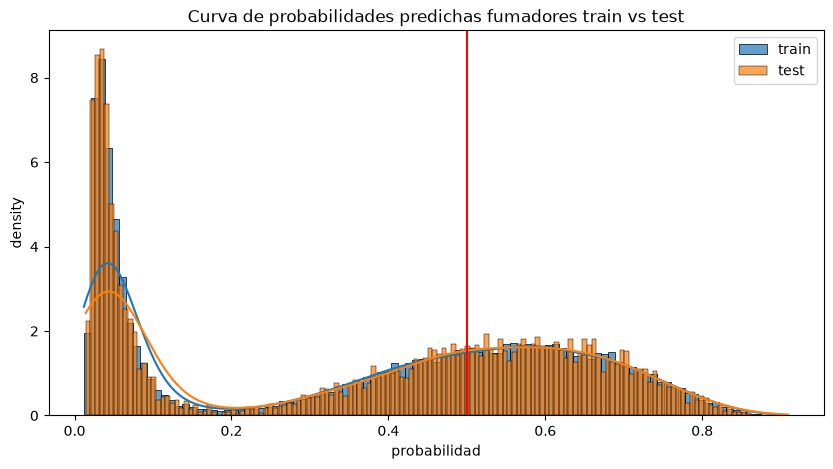

In [471]:
plt.figure(figsize=(10,5))
sns.histplot(train_pred_proba, bins=100, kde=True, label="train", stat="density", alpha=0.7)
sns.histplot(test_pred_proba, bins=150, kde=True, label="test", stat="density", alpha=0.7)
plt.axvline(0.5, color="red")
plt.title("Curva de probabilidades predichas fumadores train vs test")
plt.xlabel("probabilidad")
plt.ylabel("density")
plt.legend()
plt.show()

# Mejor umbral

In [472]:
precision, recall, thresholds = precision_recall_curve(y_test, test_pred_proba)

In [473]:
precision

array([0.3670744 , 0.3671156 , 0.36715681, ..., 1.        , 1.        ,
       1.        ], shape=(8905,))

In [474]:
recall

array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, ...,
       6.11433812e-04, 3.05716906e-04, 0.00000000e+00], shape=(8905,))

In [475]:
thresholds

array([0.01416956, 0.01503028, 0.01521337, ..., 0.86932933, 0.8878711 ,
       0.9098108 ], shape=(8904,), dtype=float32)

In [476]:
f1_score = 2 * (precision * recall) / (precision + recall)

In [477]:
f1_score

array([0.53702184, 0.53706592, 0.53711002, ..., 0.00122212, 0.00061125,
       0.        ], shape=(8905,))

In [478]:
indice_mejor = np.argmax(f1_score[:-1])   # [:-1] porque precision/recall tienen un punto extra al final
mejor_umbral = thresholds[indice_mejor]

In [486]:
print ("Indice mejor: ", indice_mejor)
print ("Mejor umbral: ", mejor_umbral)

Indice mejor:  4151
Mejor umbral:  0.4055094


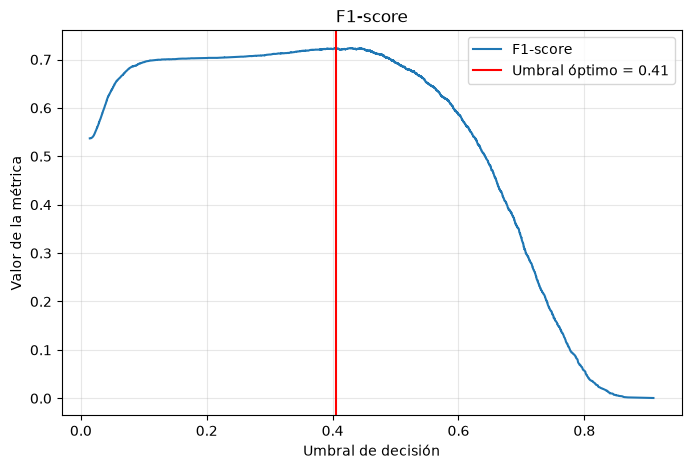

In [480]:
fig, ax = plt.subplots(figsize=(8, 5))
#ax.plot(thresholds, precision[:-1], label="Precision")
#ax.plot(thresholds, recall[:-1], label="Recall")
ax.plot(thresholds, f1_score[:-1], label="F1-score")

ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Valor de la métrica")
ax.set_title("F1-score")
plt.axvline(mejor_umbral,label=f"Umbral óptimo = {mejor_umbral:.2f}" , color="red")
ax.legend()
ax.grid(alpha=0.3)
#plt.tight_layout()
plt.show()

In [481]:
y_train_pred_custom = (train_pred_proba >= mejor_umbral).astype(int)
y_test_pred_custom = (test_pred_proba >= mejor_umbral).astype(int)

In [482]:
y_train_pred_custom

array([1, 0, 1, ..., 1, 1, 1], shape=(35641,))

In [483]:
y_test_pred_custom

array([1, 0, 0, ..., 1, 0, 1], shape=(8911,))

In [484]:
print("Train")
print(classification_report(y_train, y_train_pred_custom))
print("--------------------------------------------------------")
print("Test")
print(classification_report(y_test, y_test_pred_custom))

Train
              precision    recall  f1-score   support

           0       0.91      0.67      0.77     22560
           1       0.61      0.88      0.72     13081

    accuracy                           0.75     35641
   macro avg       0.76      0.78      0.75     35641
weighted avg       0.80      0.75      0.75     35641

--------------------------------------------------------
Test
              precision    recall  f1-score   support

           0       0.91      0.67      0.77      5640
           1       0.61      0.89      0.72      3271

    accuracy                           0.75      8911
   macro avg       0.76      0.78      0.75      8911
weighted avg       0.80      0.75      0.76      8911



In [485]:
joblib.dump((mejor_umbral), "../models/mejor_umbral.joblib")

['../models/mejor_umbral.joblib']